# Continuum fit -- SDSS J172637.24+264127.6

Goal: fit the continuum of the SDSS spectrum of the A0 star
SDSS J172637.24+264127.6 (`spec-lite-2182-53905-0101.fits`, see
`MAST_query.ipynb`) with `continuum.fit_continuum`, and normalise it
for the line fitting.

Method: cubic spline with knots every `knot_spacing` Angstrom, weighted
by 1/sigma. Pixels more than `clip_low` sigma below the fit are
rejected, and the spline is refitted until convergence. Only pixels below
are clipped, because absorption only removes flux: the first fits run through the lines,
below the true continuum, so a cut above would reject the continuum
itself. Every pixel is re-tested at each iteration, so the fit rises
step by step to the continuum.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from spectral_diag.continuum import ContinuumSettings, fit_continuum, normalise
from spectral_diag.io import read_sdss_spec

In [2]:
spec = read_sdss_spec(Path("../data/mast/spec-lite-2182-53905-0101.fits"))
print(f"{spec.meta['class']} {spec.meta['subclass']}, z = {spec.meta['z']:.5f}")
print(f"{spec.wave.size} pixels, {spec.wave.min():.1f}-{spec.wave.max():.1f} A")

STAR A0, z = -0.00012
3772 pixels, 3811.5-9206.6 A


## Fit

Default settings. Red points: pixels clipped in the final fit, a
first, line-list-free view of where the absorption is.

ContinuumSettings(knot_spacing=150.0, clip_low=2.0, clip_high=inf, max_iter=20)
3179 of 3772 pixels used


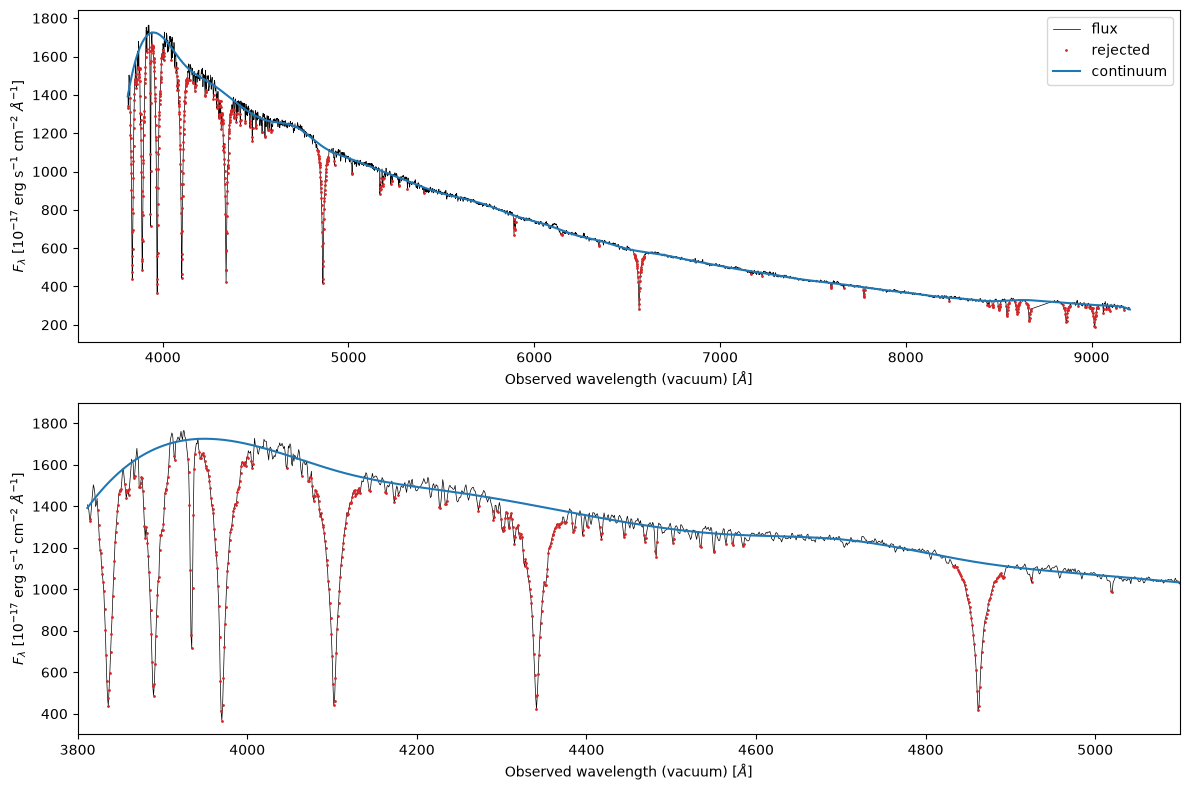

In [3]:
# Zoom on the blue end, where the absorption is strongest (Angstrom,
# flux units)
BLUE_WAVE_RANGE = (3800, 5100)
BLUE_FLUX_RANGE = (300, 1900)

settings = ContinuumSettings()
print(settings)
continuum, used = fit_continuum(spec, settings)
print(f"{used.sum()} of {used.size} pixels used")


def plot_fit(ax, spec, continuum, used):
    """Plot flux, rejected pixels and continuum on `ax`.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
    spec : Spectrum
    continuum : array
    used : array of bool
    """
    ax.plot(spec.wave, spec.flux, lw=0.5, color="k", label="flux")
    ax.plot(spec.wave[~used], spec.flux[~used], ".", ms=2, color="C3",
            label="rejected")
    ax.plot(spec.wave, continuum, color="C0", label="continuum")
    ax.set_xlabel(r"Observed wavelength (vacuum) [$\AA$]")
    ax.set_ylabel(r"$F_\lambda$ [$10^{-17}$ erg s$^{-1}$ cm$^{-2}$ $\AA^{-1}$]")


fig, (ax_full, ax_blue) = plt.subplots(2, 1, figsize=(12, 8))
plot_fit(ax_full, spec, continuum, used)
ax_full.legend()
plot_fit(ax_blue, spec, continuum, used)
ax_blue.set_xlim(*BLUE_WAVE_RANGE)
ax_blue.set_ylim(*BLUE_FLUX_RANGE)
plt.tight_layout()
plt.show()

Here the continuum covers the whole spectrum. If the first or last
pixels were clipped, `fit_continuum` would leave the continuum as NaN
beyond the used pixels instead of extrapolating the spline, which
diverges.

Below ~3900 A the spline follows the overlapping wings of the higher
Balmer lines as they converge towards the series limit at 3646 A: no
pixel there reaches the continuum, so the fit is too low. The line
fitting will correct it with a local continuum.

## Knot spacing

The main parameter. Too small: the spline has the freedom to follow
the broad lines and eats part of their equivalent width. Too large: it
cannot follow the real shape of the continuum.

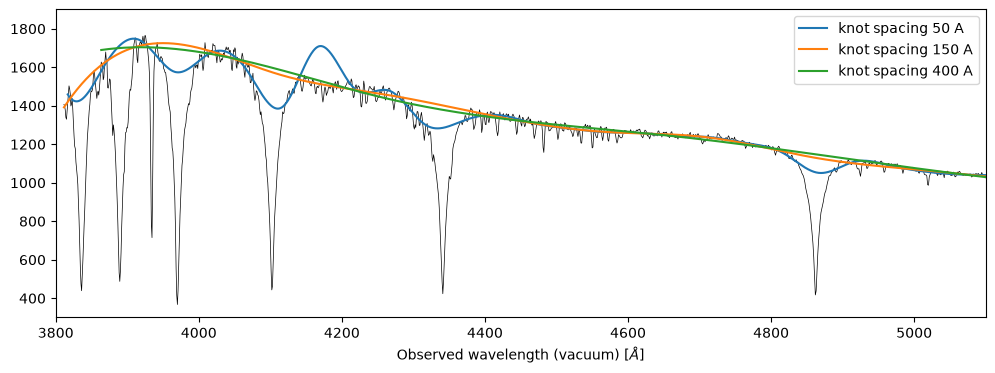

In [4]:
KNOT_SPACINGS = [50.0, 150.0, 400.0]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(spec.wave, spec.flux, lw=0.5, color="k")
for knot_spacing in KNOT_SPACINGS:
    trial, _ = fit_continuum(spec, ContinuumSettings(knot_spacing=knot_spacing))
    ax.plot(spec.wave, trial, label=f"knot spacing {knot_spacing:.0f} A")
ax.set_xlim(*BLUE_WAVE_RANGE)
ax.set_ylim(*BLUE_FLUX_RANGE)
ax.set_xlabel(r"Observed wavelength (vacuum) [$\AA$]")
ax.legend()
plt.show()

## Normalised spectrum

Flux and error divided by the continuum: the input for the equivalent
widths and the line fitting.

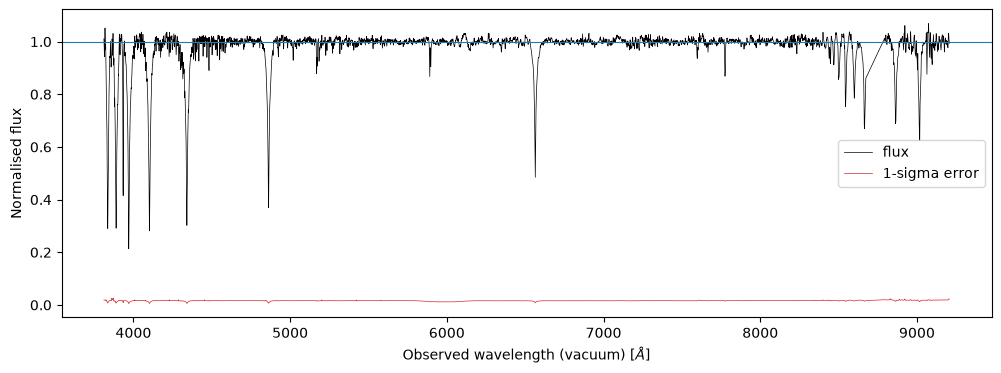

std of normalised flux in used pixels: 0.0122
median normalised error:               0.0162


In [5]:
normalised = normalise(spec, continuum)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(normalised.wave, normalised.flux, lw=0.5, color="k", label="flux")
ax.plot(normalised.wave, normalised.error, lw=0.5, color="C3",
        label="1-sigma error")
ax.axhline(1, color="C0", lw=0.8)
ax.set_xlabel(r"Observed wavelength (vacuum) [$\AA$]")
ax.set_ylabel("Normalised flux")
ax.legend()
plt.show()

good = np.isfinite(normalised.flux) & used
print(f"std of normalised flux in used pixels: {np.std(normalised.flux[good]):.4f}")
print(f"median normalised error:               {np.median(normalised.error[good]):.4f}")

## Limitations

- The knot spacing is chosen by comparing fits by eye.
- In the used pixels the scatter of the normalised flux is ~25%
  smaller than the median SDSS error. Clipping at 2 sigma explains only
  ~6% (the std of a normal truncated at -2 sigma is 0.94); the rest is
  not explained yet.
- The normalised error does not include the uncertainty of the
  continuum.
- Where the wings of neighbouring broad lines overlap, even the flux
  between them may sit below the true continuum, and the fit follows
  it. A fit of each line together with a local continuum would be
  more accurate.